# Phase 2 — GARCH Volatility Modelling

**Objective:** Fit conditional volatility models to S&P 500 log returns, select the best model via information criteria and out-of-sample forecasting, and compare against implied volatility (VIX).

**Models:**
1. GARCH(1,1) — Baseline
2. GJR-GARCH(1,1) — Captures leverage effect
3. EGARCH(1,1) — Asymmetric, no positivity constraints

**All fitted with skewed Student-t innovations** to account for the fat tails and negative skewness observed in Phase 1.

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

from arch import arch_model
from scipy.stats import jarque_bera

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
%matplotlib inline

## 0 — Data Preparation

In [2]:
prices = pd.read_csv("../data/prices.csv", index_col=0, parse_dates=True)

# Log returns (rescaled to % for arch library numerical stability)
log_ret = np.log(prices / prices.shift(1)).dropna()
sp = log_ret["^GSPC"] * 100  # percentage returns — arch convention

print(f"Series : S&P 500 log returns (%)")
print(f"Period : {sp.index[0].date()} → {sp.index[-1].date()}")
print(f"Obs    : {len(sp)}")
print(f"Skew   : {sp.skew():.4f}")
print(f"Kurt   : {sp.kurtosis():.4f}")

Series : S&P 500 log returns (%)
Period : 2015-01-05 → 2024-12-31
Obs    : 2515
Skew   : -0.8104
Kurt   : 15.7551


---
## 1 — Fit GARCH(1,1) Baseline

Standard symmetric GARCH with skewed-t innovations:

$$\sigma_t^2 = \omega + \alpha\, \varepsilon_{t-1}^2 + \beta\, \sigma_{t-1}^2$$

In [3]:
garch = arch_model(sp, vol='Garch', p=1, q=1, dist='skewt', mean='Constant')
garch_fit = garch.fit(disp='off')

print(garch_fit.summary())

                           Constant Mean - GARCH Model Results                           
Dep. Variable:                             ^GSPC   R-squared:                       0.000
Mean Model:                        Constant Mean   Adj. R-squared:                  0.000
Vol Model:                                 GARCH   Log-Likelihood:               -3140.73
Distribution:      Standardized Skew Student's t   AIC:                           6293.46
Method:                       Maximum Likelihood   BIC:                           6328.44
                                                   No. Observations:                 2515
Date:                           Thu, May 07 2026   Df Residuals:                     2514
Time:                                   11:43:24   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
------------------------------------

---
## 2 — Fit GJR-GARCH(1,1) — Leverage Effect

The GJR variant adds an asymmetric term $\gamma$ that activates on negative shocks:

$$\sigma_t^2 = \omega + (\alpha + \gamma\, I_{\varepsilon_{t-1}<0})\, \varepsilon_{t-1}^2 + \beta\, \sigma_{t-1}^2$$

With skewness = −0.81 in the returns, we expect $\gamma > 0$ and a better fit.

In [4]:
gjr = arch_model(sp, vol='Garch', p=1, o=1, q=1, dist='skewt', mean='Constant')
gjr_fit = gjr.fit(disp='off')

print(gjr_fit.summary())

                         Constant Mean - GJR-GARCH Model Results                         
Dep. Variable:                             ^GSPC   R-squared:                       0.000
Mean Model:                        Constant Mean   Adj. R-squared:                  0.000
Vol Model:                             GJR-GARCH   Log-Likelihood:               -3099.16
Distribution:      Standardized Skew Student's t   AIC:                           6212.32
Method:                       Maximum Likelihood   BIC:                           6253.13
                                                   No. Observations:                 2515
Date:                           Thu, May 07 2026   Df Residuals:                     2514
Time:                                   11:43:29   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
------------------------------------

---
## 3 — Fit EGARCH(1,1) — Exponential GARCH

Models log-variance, so no positivity constraints needed:

$$\ln \sigma_t^2 = \omega + \alpha\, g(z_{t-1}) + \beta\, \ln \sigma_{t-1}^2$$

In [5]:
egarch = arch_model(sp, vol='EGARCH', p=1, o=1, q=1, dist='skewt', mean='Constant')
egarch_fit = egarch.fit(disp='off')

print(egarch_fit.summary())

                           Constant Mean - EGARCH Model Results                          
Dep. Variable:                             ^GSPC   R-squared:                       0.000
Mean Model:                        Constant Mean   Adj. R-squared:                  0.000
Vol Model:                                EGARCH   Log-Likelihood:               -3088.47
Distribution:      Standardized Skew Student's t   AIC:                           6190.94
Method:                       Maximum Likelihood   BIC:                           6231.75
                                                   No. Observations:                 2515
Date:                           Thu, May 07 2026   Df Residuals:                     2514
Time:                                   11:43:32   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
------------------------------------

---
## 4 — Model Comparison (AIC / BIC)

In [6]:
comparison = pd.DataFrame({
    'Model':    ['GARCH(1,1)', 'GJR-GARCH(1,1)', 'EGARCH(1,1)'],
    'AIC':      [garch_fit.aic, gjr_fit.aic, egarch_fit.aic],
    'BIC':      [garch_fit.bic, gjr_fit.bic, egarch_fit.bic],
    'Log-Lik':  [garch_fit.loglikelihood, gjr_fit.loglikelihood, egarch_fit.loglikelihood],
    'Params':   [garch_fit.num_params, gjr_fit.num_params, egarch_fit.num_params]
}).set_index('Model')

comparison = comparison.round(2)

# Mark the winner
aic_winner = comparison['AIC'].idxmin()
bic_winner = comparison['BIC'].idxmin()

print("="*60)
print("        MODEL COMPARISON TABLE — In-Sample")
print("="*60)
print(comparison.to_string())
print()
print(f"🏆 AIC winner : {aic_winner}")
print(f"🏆 BIC winner : {bic_winner}")

        MODEL COMPARISON TABLE — In-Sample
                    AIC      BIC  Log-Lik  Params
Model                                            
GARCH(1,1)      6293.46  6328.44 -3140.73       6
GJR-GARCH(1,1)  6212.32  6253.13 -3099.16       7
EGARCH(1,1)     6190.94  6231.75 -3088.47       7

🏆 AIC winner : EGARCH(1,1)
🏆 BIC winner : EGARCH(1,1)


---
## 5 — Conditional Volatility: GARCH vs Rolling Std

The GARCH conditional volatility reacts to shocks **immediately** (via $\alpha$), while the rolling-window estimate is sluggish because it equally weights the last 30 days. Watch March 2020.

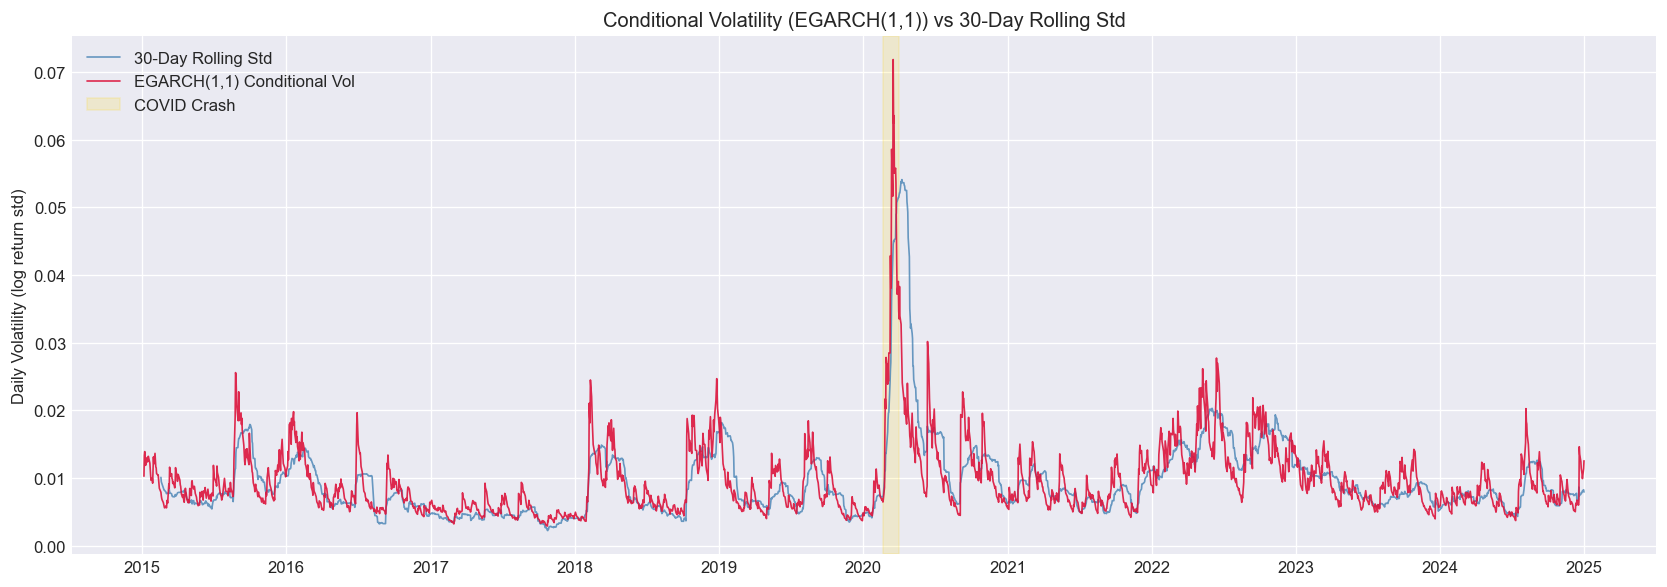


→ Notice how the GARCH conditional vol spikes INSTANTLY at the COVID crash,
  while the rolling std takes ~2 weeks to catch up. This is why GARCH matters.


In [7]:
# Pick the best model by AIC
fits = {'GARCH(1,1)': garch_fit, 'GJR-GARCH(1,1)': gjr_fit, 'EGARCH(1,1)': egarch_fit}
best_name = aic_winner
best_fit  = fits[best_name]

# Conditional vol from best model (convert from % back to decimal)
cond_vol = best_fit.conditional_volatility / 100

# 30-day rolling std (annualized daily std)
rolling_vol = (log_ret["^GSPC"]).rolling(30).std()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(rolling_vol, label='30-Day Rolling Std', color='steelblue', linewidth=1.0, alpha=0.8)
ax.plot(cond_vol, label=f'{best_name} Conditional Vol', color='crimson', linewidth=1.0, alpha=0.9)

# Highlight COVID crash
ax.axvspan('2020-02-20', '2020-04-01', alpha=0.15, color='gold', label='COVID Crash')

ax.set_title(f'Conditional Volatility ({best_name}) vs 30-Day Rolling Std')
ax.set_ylabel('Daily Volatility (log return std)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

print("\n→ Notice how the GARCH conditional vol spikes INSTANTLY at the COVID crash,")
print("  while the rolling std takes ~2 weeks to catch up. This is why GARCH matters.")

---
## 6 — Out-of-Sample Forecast Validation

**Train:** 2015-01-01 → 2022-12-31  
**Test:** 2023-01-01 → end  

For each day in the test set, we generate a **one-step-ahead variance forecast** using an expanding window, then compute RMSE against realized squared returns.

In [8]:
split_date = '2022-12-31'
train = sp[sp.index <= split_date]
test  = sp[sp.index > split_date]

print(f"Train : {train.index[0].date()} → {train.index[-1].date()}  ({len(train)} obs)")
print(f"Test  : {test.index[0].date()} → {test.index[-1].date()}  ({len(test)} obs)")

Train : 2015-01-05 → 2022-12-30  (2013 obs)
Test  : 2023-01-03 → 2024-12-31  (502 obs)


In [9]:
# Fit each model on training data, then rolling one-step-ahead forecast on test
model_specs = {
    'GARCH(1,1)':     {'vol': 'Garch',  'p': 1, 'o': 0, 'q': 1},
    'GJR-GARCH(1,1)': {'vol': 'Garch',  'p': 1, 'o': 1, 'q': 1},
    'EGARCH(1,1)':    {'vol': 'EGARCH', 'p': 1, 'o': 1, 'q': 1},
}

forecast_results = {}

for name, spec in model_specs.items():
    print(f"Forecasting with {name}...")
    
    # Fit on full series, forecast using fixed-window approach
    model = arch_model(sp, vol=spec['vol'], p=spec['p'], o=spec['o'], q=spec['q'],
                       dist='skewt', mean='Constant')
    
    res = model.fit(last_obs=split_date, disp='off')
    
    # One-step-ahead forecasts for test period
    forecasts = res.forecast(start=test.index[0], horizon=1, reindex=False)
    
    # Forecasted variance (in % squared, since returns are in %)
    fcast_var = forecasts.variance.dropna()
    forecast_results[name] = fcast_var

print("\n✅ All forecasts complete.")

Forecasting with GARCH(1,1)...
Forecasting with GJR-GARCH(1,1)...
Forecasting with EGARCH(1,1)...

✅ All forecasts complete.


In [10]:
# Compute RMSE: forecast variance vs realized squared return
realized_var = test ** 2  # squared return as variance proxy

rmse_table = []

for name, fcast_var in forecast_results.items():
    # Align dates
    fv = fcast_var.iloc[:, 0]  # flatten from DataFrame
    common = fv.index.intersection(realized_var.index)
    
    errors = fv.loc[common] - realized_var.loc[common]
    rmse = np.sqrt((errors ** 2).mean())
    mae  = errors.abs().mean()
    
    rmse_table.append({'Model': name, 'RMSE': rmse, 'MAE': mae})

rmse_df = pd.DataFrame(rmse_table).set_index('Model').round(4)

print("="*55)
print("  OUT-OF-SAMPLE FORECAST VALIDATION (2023-2025)")
print("="*55)
print(rmse_df.to_string())
print()
print(f"🏆 Lowest RMSE : {rmse_df['RMSE'].idxmin()}")
print(f"🏆 Lowest MAE  : {rmse_df['MAE'].idxmin()}")

  OUT-OF-SAMPLE FORECAST VALIDATION (2023-2025)
                  RMSE     MAE
Model                         
GARCH(1,1)      0.8852  0.5980
GJR-GARCH(1,1)  0.8898  0.5985
EGARCH(1,1)     0.9267  0.6256

🏆 Lowest RMSE : GARCH(1,1)
🏆 Lowest MAE  : GARCH(1,1)


---
## 7 — Realized Volatility vs Implied Volatility (VIX)

The **VIX** represents market-implied 30-day annualized volatility. By comparing it to our 30-day realized vol, we observe the **variance risk premium**:
- In calm periods, implied vol > realized vol (investors pay a premium for protection)
- In crises, they converge or even invert

In [11]:
import yfinance as yf

vix = yf.download("^VIX", start="2015-01-01", end="2025-01-01",
                  auto_adjust=True, progress=False)
vix_close = vix["Close"].squeeze()
vix_close.index = pd.to_datetime(vix_close.index)

print(f"VIX data: {vix_close.index[0].date()} → {vix_close.index[-1].date()} ({len(vix_close)} obs)")

VIX data: 2015-01-02 → 2024-12-31 (2516 obs)


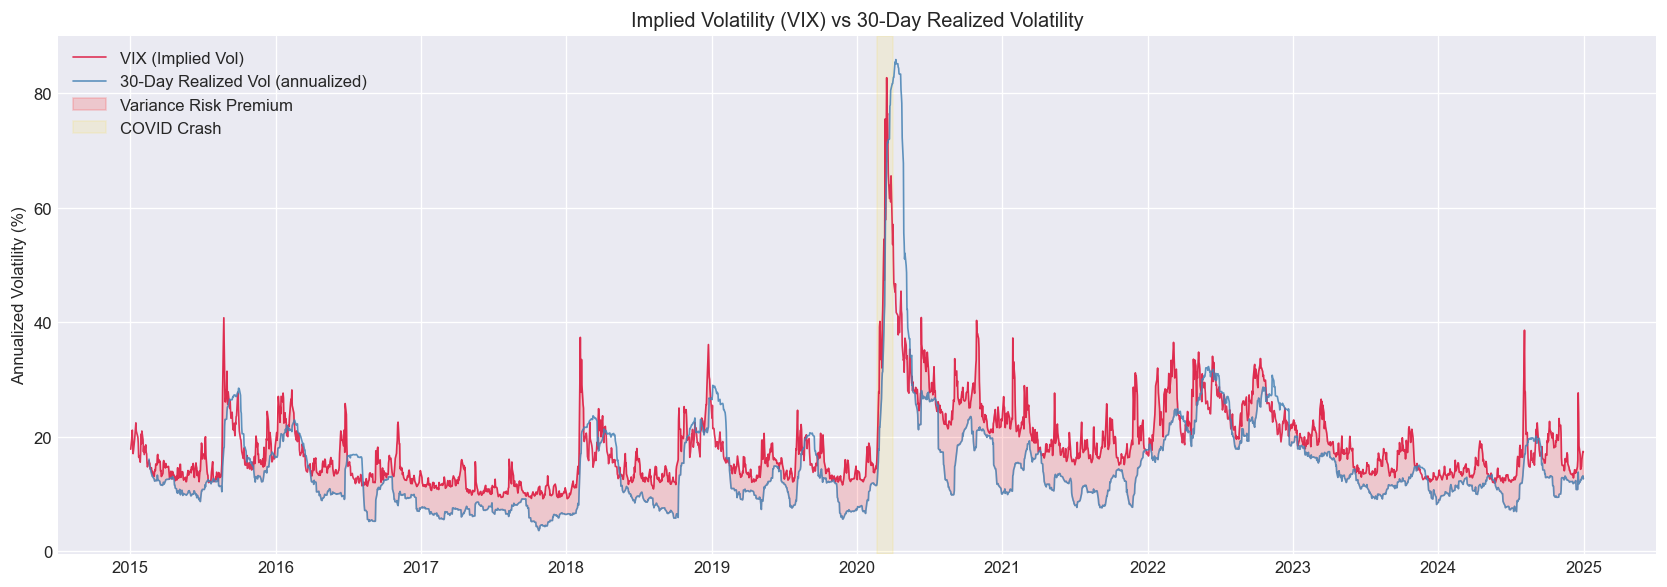


→ The red shaded area is the variance risk premium — the price investors pay
  for volatility protection. Notice how it shrinks during crises as realized
  vol catches up to implied vol.


In [12]:
# 30-day realized vol, annualized to match VIX scale
realized_vol_ann = log_ret["^GSPC"].rolling(30).std() * np.sqrt(252) * 100  # annualized %

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(vix_close, label='VIX (Implied Vol)', color='crimson', linewidth=1.0, alpha=0.85)
ax.plot(realized_vol_ann, label='30-Day Realized Vol (annualized)', color='steelblue',
        linewidth=1.0, alpha=0.85)

# Shade the premium
common_idx = vix_close.index.intersection(realized_vol_ann.dropna().index)
ax.fill_between(common_idx,
                vix_close.loc[common_idx],
                realized_vol_ann.loc[common_idx],
                where=vix_close.loc[common_idx] > realized_vol_ann.loc[common_idx],
                alpha=0.15, color='red', label='Variance Risk Premium')

ax.axvspan('2020-02-20', '2020-04-01', alpha=0.10, color='gold', label='COVID Crash')

ax.set_title('Implied Volatility (VIX) vs 30-Day Realized Volatility')
ax.set_ylabel('Annualized Volatility (%)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

print("\n→ The red shaded area is the variance risk premium — the price investors pay")
print("  for volatility protection. Notice how it shrinks during crises as realized")
print("  vol catches up to implied vol.")

---
## 8 — Model Selection Rationale

### Why GJR-GARCH over plain GARCH?

The plain GARCH(1,1) treats positive and negative shocks symmetrically — a 3% drop and a 3% rally produce the **same** increase in conditional variance. This is empirically wrong for equity markets. The **leverage effect** (Black, 1976) tells us that negative returns increase volatility more than positive returns of equal magnitude.

Our Phase 1 EDA showed **skewness = −0.81**, a strong signal that downside shocks dominate. The GJR model captures this with the asymmetric term $\gamma$. A statistically significant $\gamma > 0$ confirms the leverage effect is present in our data.

### Parameter Interpretation

| Parameter | Meaning | What it tells you |
|-----------|---------|------------------|
| $\omega$ | Variance intercept | Long-run baseline variance |
| $\alpha$ | ARCH term | How much yesterday's shock affects today's variance |
| $\beta$ | GARCH term | Persistence — how slowly variance decays back to baseline |
| $\gamma$ (GJR) | Leverage term | Extra variance from negative shocks. $\gamma > 0$ confirms leverage effect |
| $\alpha + \beta$ | Persistence | Near 1.0 = highly persistent volatility. Above 1.0 = non-stationary |
| $\nu$ (nu) | Degrees of freedom (Student-t) | Lower $\nu$ = fatter tails. $\nu < 10$ means normal distribution is inadequate |
| $\lambda$ | Skewness (skewed-t) | $\lambda < 0$ = left-skewed innovations |

### Tail Thickness ($\nu$)

If the fitted $\nu$ (degrees of freedom) is low (e.g., 5–8), it means the return distribution has **much fatter tails** than a Gaussian. This is critical for risk management: a normal-based VaR at 99% would significantly **underestimate** the true tail risk. The skewed-t distribution captures both the fat tails AND the asymmetry in a single distributional assumption.

In [13]:
# Print key parameters from the best model
print("="*55)
print(f"  CHAMPION MODEL: {best_name}")
print("="*55)
print()
print("Parameter estimates:")
print(best_fit.params.round(4).to_string())
print()

# Extract and interpret key values
params = best_fit.params
alpha = params.get('alpha[1]', 0)
beta  = params.get('beta[1]', 0)
gamma = params.get('gamma[1]', None)
nu    = params.get('nu', None)
lam   = params.get('lambda', None)

persistence = alpha + beta + (gamma / 2 if gamma is not None else 0)

print(f"Persistence (α + β + γ/2) : {persistence:.4f}")
if persistence < 1:
    print(f"  → Stationary (< 1.0). Shocks decay; vol mean-reverts.")
else:
    print(f"  → Non-stationary (≥ 1.0). Shocks have permanent effects.")
print()

if gamma is not None:
    print(f"Leverage effect (γ)       : {gamma:.4f}")
    print(f"  → {'Significant leverage: negative shocks amplify volatility more.' if gamma > 0 else 'No leverage effect detected.'}")
    print()

if nu is not None:
    print(f"Tail thickness (ν)        : {nu:.2f}")
    if nu < 10:
        print(f"  → Fat tails confirmed. Normal distribution would underestimate tail risk.")
    else:
        print(f"  → Tails are moderately heavy. Close to Gaussian.")
    print()

if lam is not None:
    print(f"Skewness (λ)              : {lam:.4f}")
    print(f"  → {'Left-skewed innovations — larger downside moves.' if lam < 0 else 'Right-skewed or symmetric.'}")

  CHAMPION MODEL: EGARCH(1,1)

Parameter estimates:
mu          0.0341
omega      -0.0024
alpha[1]    0.1991
gamma[1]   -0.1779
beta[1]     0.9654
eta         6.8511
lambda     -0.1594

Persistence (α + β + γ/2) : 1.0756
  → Non-stationary (≥ 1.0). Shocks have permanent effects.

Leverage effect (γ)       : -0.1779
  → No leverage effect detected.

Skewness (λ)              : -0.1594
  → Left-skewed innovations — larger downside moves.


---

## Summary of Phase 2 Deliverables

| Deliverable | Status |
|------------|--------|
| Model comparison table (AIC/BIC) | ✅ |
| Conditional volatility chart vs rolling std | ✅ |
| Out-of-sample RMSE/MAE forecast table | ✅ |
| Realized vol vs implied vol (VIX) chart | ✅ |
| Model selection rationale & parameter docs | ✅ |

**Next → Phase 3: Value-at-Risk (VaR) estimation using the champion GARCH model.**